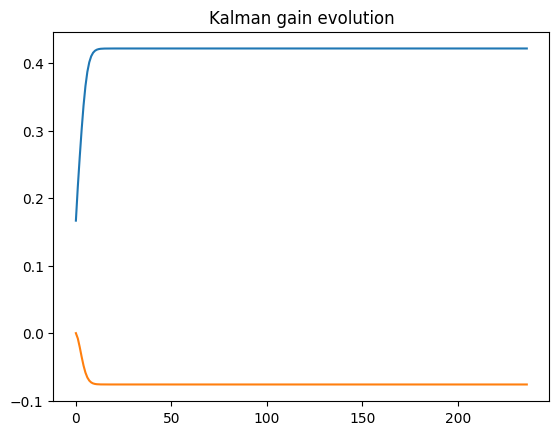

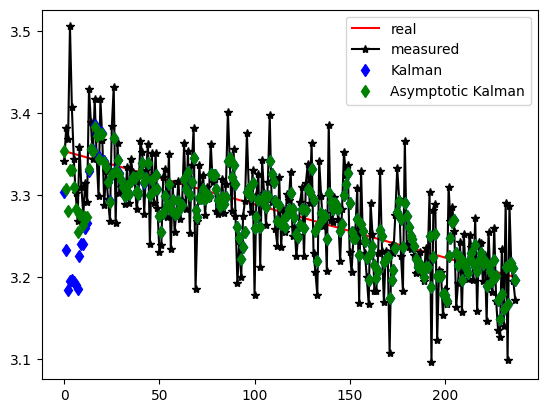

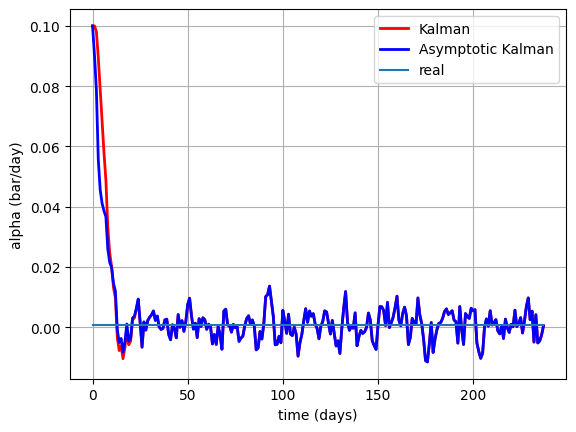

In [71]:
# entire range visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.close('all')

# =========================
# 1. 从文件读取“真实系统”的初始值
# =========================
df = pd.read_csv("/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv", encoding="utf-8-sig")

# target_csemCur = 5002343705   # target csemCur
target_csemCur = 5000252545
df_csem = df[df['csemCur'] == target_csemCur].copy()

if df_csem.empty:
    raise ValueError(f"在 new_df_AlphaCorrected 中没有找到 csemCur = {target_csemCur} 的数据")

# 如果同一个 csemCur 有多行，这里先取第一行
row0 = df_csem.iloc[0]

P0_true = float(row0['compensatedRelativePressure_mafiltered']) # read real P0 from the file
alpha_true = float(row0['alpha']) # read real alpha from the file
# alpha_true = 0.001

# =========================
# 2. 真实系统仍按线性方式变化
# =========================
Te = 1.0    # sampling time (days)
tf = (P0_true - 3.2) / alpha_true
temps = np.arange(0, tf + Te, Te)

P_true = P0_true - temps * alpha_true

# Noise
P_measured = P_true + 0.05 * np.random.randn(len(P_true))

# Plot of pressure
plt.figure(1)
plt.plot(temps, P_true, 'r', label='real pressure')
plt.plot(temps, P_measured, '*-k', label='measured pressure')

# =========================
# 3. Kalman filtering
# =========================
Q = Te * np.diag([0.01, 1e-3])
R = 0.1
Sigma_priori = np.diag([0.01, 1e-6])

# Initialisation
alpha0 = 0.1
P0 = P0_true - 0.05    # 这里也可以改成别的初始猜测，比如 P0_true - 0.05

x0 = np.array([[P0], [alpha0]])
Kalman_states = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])
Kalman_gain = np.empty((2, 0))

for k in range(len(temps) - 1):
    A = np.array([[1, -Te],
                  [0,  1]])

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    K = Sigma_priori @ H.T @ np.linalg.inv(np.array([[R]]) + H @ Sigma_priori @ H.T)
    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori

    x_posteriori = x_priori + K @ (np.array([[P_measured[k + 1]]]) - H @ x_priori)

    Kalman_states = np.hstack((Kalman_states, x_posteriori))
    Kalman_gain = np.hstack((Kalman_gain, K))

P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]

plt.figure(1)
plt.plot(temps, P_Kalman, 'bd', label='Kalman')

plt.figure(2)
plt.plot(temps, alpha_Kalman, 'r', linewidth=2, label='Kalman')
plt.grid(True)
plt.xlabel('Temps (days)')
plt.ylabel('alpha (bar/day)')

plt.figure(3)
plt.plot(Kalman_gain.T)
plt.title('Kalman gain evolution')

# =========================
# 4. Asymptotic Kalman filter
# =========================
alpha0 = 0.1
P0 = P0_true

x0 = np.array([[P0], [alpha0]])
Kalman_states2 = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])

K = Kalman_gain[:, -1].reshape(2, 1)

for k in range(len(temps) - 1):
    A = np.array([[1, -Te],
                  [0,  1]])

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori
    x_posteriori = x_priori + K @ (np.array([[P_measured[k + 1]]]) - H @ x_priori)

    Kalman_states2 = np.hstack((Kalman_states2, x_posteriori))

P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]

plt.figure(1)
plt.plot(temps, P_Kalman2, 'gd', label='Asymptotic Kalman')
plt.legend(['real', 'measured', 'Kalman', 'Asymptotic Kalman'])

plt.figure(2)
plt.plot(temps, alpha_Kalman2, 'b', linewidth=2, label='Asymptotic Kalman')
plt.plot(temps, alpha_true * np.ones_like(temps), label='real')
plt.xlabel('time (days)')
plt.ylabel('alpha (bar/day)')
plt.legend(['Kalman', 'Asymptotic Kalman', 'real'])

plt.show()

target_csemCur = 5000252545
P0_true = 3.353635650097035
alpha_true = 0.0006485958289678
tf = 236.87424931723112
x_max_zoom = 200


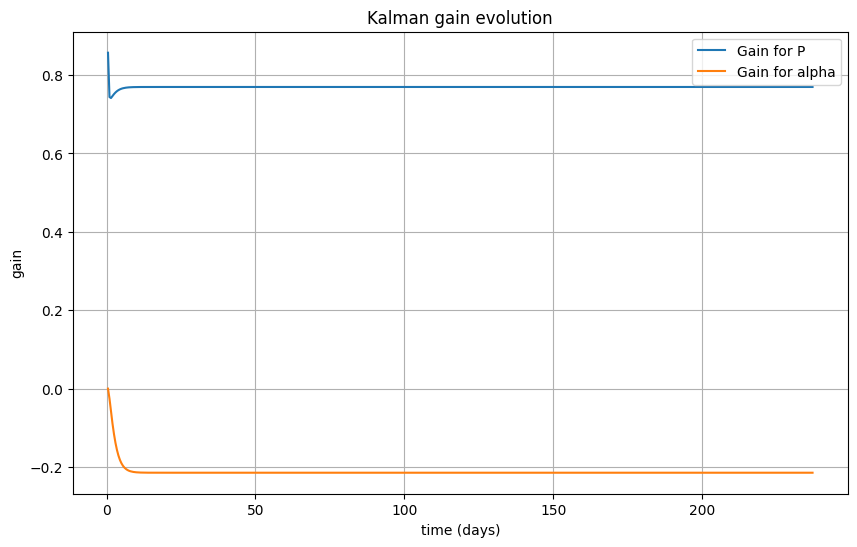

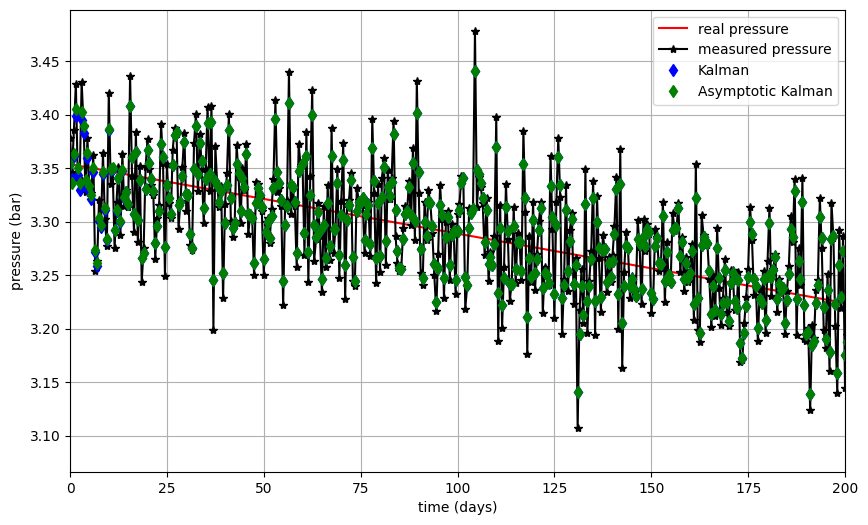

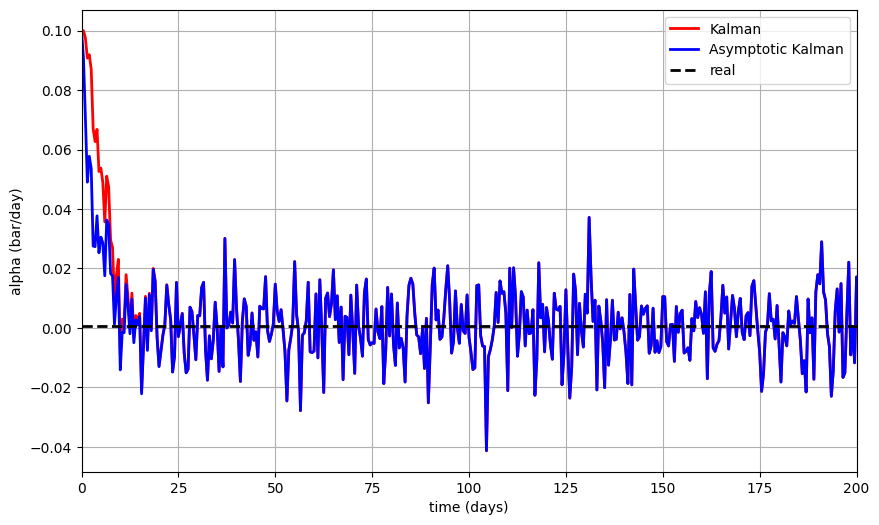

In [80]:
# visualization change - just check first x days

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 0. 基本设置
# =========================
plt.close('all')
np.random.seed(42)   # 为了结果可复现，可删除

# =========================
# 1. 读取真实系统初始值
# =========================
df = pd.read_csv("/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv", encoding="utf-8-sig")

# target_csemCur = 5002343705   # target csemCur
target_csemCur = 5000252545

df_csem = df[df['csemCur'] == target_csemCur].copy()

if df_csem.empty:
    raise ValueError(f"在 new_df_AlphaCorrected 中没有找到 csemCur = {target_csemCur} 的数据")

# 如果同一个 csemCur 有多行：
# - 如果你有时间列，建议先 sort_values('date') 再取最后一行
# - 这里先简单取第一行
row0 = df_csem.iloc[0]

# 真实系统参数：从文件读
P0_true = float(row0['compensatedRelativePressure_mafiltered'])
alpha_true = float(row0['alpha']) # read real alpha from the file
# alpha_true = 0.01 # if set a fixed value, you can change it here

# =========================
# 2. 真实系统线性变化
# =========================
Te = 0.5   # sampling time

if alpha_true <= 0:
    raise ValueError(f"alpha_true 必须大于 0，当前读取到的是 {alpha_true}")

tf = (P0_true - 3.2) / alpha_true

if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查 P0_true={P0_true} 和 alpha_true={alpha_true}"
    )

temps = np.arange(0, tf + Te, Te)

# 真实系统仍按线性方式变化
P_true = P0_true - temps * alpha_true

# Noise
sigma_meas = 0.05
# sigma_meas = 0.001
P_measured = P_true + sigma_meas * np.random.randn(len(P_true))

# =========================
# 3. 先画压力图（完整范围）
# =========================
plt.figure(1, figsize=(10, 6))
plt.plot(temps, P_true, 'r', label='real pressure')
plt.plot(temps, P_measured, '*-k', label='measured pressure')

# =========================
# 4. Kalman filtering
# =========================
Q = Te * np.diag([0.01, 1e-3])
R = sigma_meas**2
Sigma_priori_init = np.diag([0.01, 1e-6])

# Initialisation
# 这里是滤波器的初始猜测，不是真实值
alpha0 = 0.1
P0 = P0_true   # 也可以设成 P0_true - 0.05，看你是否想故意给一个偏差

x0 = np.array([[P0],
               [alpha0]])

Kalman_states = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])
Kalman_gain = np.empty((2, 0))

for k in range(len(temps) - 1):
    A = np.array([[1, -Te],
                  [0,  1]])   # prediction matrix, Euler discretization

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    K = Sigma_priori @ H.T @ np.linalg.inv(np.array([[R]]) + H @ Sigma_priori @ H.T)
    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori

    innovation = np.array([[P_measured[k + 1]]]) - H @ x_priori
    x_posteriori = x_priori + K @ innovation

    Kalman_states = np.hstack((Kalman_states, x_posteriori))
    Kalman_gain = np.hstack((Kalman_gain, K))

P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]

plt.figure(1)
plt.plot(temps, P_Kalman, 'bd', label='Kalman')

# =========================
# 5. Asymptotic Kalman filter
# =========================
alpha0_2 = 0.1
P0_2 = P0_true

x0 = np.array([[P0_2],
               [alpha0_2]])

Kalman_states2 = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])

# 固定为普通 Kalman 最后一步的增益
K = Kalman_gain[:, -1].reshape(2, 1)

for k in range(len(temps) - 1):
    A = np.array([[1, -Te],
                  [0,  1]])

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori

    innovation = np.array([[P_measured[k + 1]]]) - H @ x_priori
    x_posteriori = x_priori + K @ innovation

    Kalman_states2 = np.hstack((Kalman_states2, x_posteriori))

P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]

plt.figure(1)
plt.plot(temps, P_Kalman2, 'gd', label='Asymptotic Kalman')
plt.xlabel('time (days)')
plt.ylabel('pressure (bar)')
plt.grid(True)
plt.legend()

# =========================
# 6. alpha 图
# =========================
plt.figure(2, figsize=(10, 6))
plt.plot(temps, alpha_Kalman, 'r', linewidth=2, label='Kalman')
plt.plot(temps, alpha_Kalman2, 'b', linewidth=2, label='Asymptotic Kalman')
plt.plot(temps, alpha_true * np.ones_like(temps), 'k--', linewidth=2, label='real')
plt.grid(True)
plt.xlabel('time (days)')
plt.ylabel('alpha (bar/day)')
plt.legend()

# =========================
# 7. Kalman gain 图
# =========================
# plt.figure(3, figsize=(10, 6))
# plt.plot(Kalman_gain.T)
# plt.title('Kalman gain evolution')
# plt.xlabel('iteration')
# plt.ylabel('gain')
# plt.grid(True)


# 如果x轴单位是时间而不是迭代次数，你可以改成：
plt.figure(3, figsize=(10, 6))
plt.plot(temps[1:], Kalman_gain[0, :], label='Gain for P')
plt.plot(temps[1:], Kalman_gain[1, :], label='Gain for alpha')
plt.title('Kalman gain evolution')
plt.xlabel('time (days)')
plt.ylabel('gain')
plt.grid(True)
plt.legend()

# =========================
# 8. 放大 x 轴前段
# =========================
# 因为 alpha 小时，tf 会很大，所以这里不改 y 轴，而是只显示前段时间
x_max_zoom = min(200, temps[-1])   # 你也可以改成 100，200，或者别的值

plt.figure(1)
plt.xlim(0, x_max_zoom)

plt.figure(2)
plt.xlim(0, x_max_zoom)

# 如果你也想让 gain 图保持原样，就不要对 figure(3) 设置 xlim

# =========================
# 9. 打印关键信息
# =========================
print("target_csemCur =", target_csemCur)
print("P0_true =", P0_true)
print("alpha_true =", alpha_true)
print("tf =", tf)
print("x_max_zoom =", x_max_zoom)

plt.show()

target_csemCur = 5000252545
P0_true = 3.353635650097035
alpha_true = 0.0006485958289678
tf = 236.87424931723112
x_max_zoom = 237.0


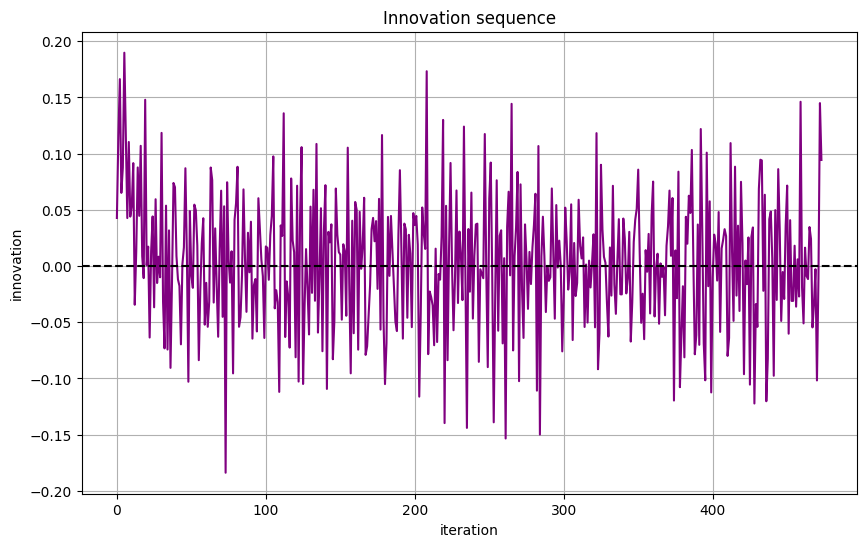

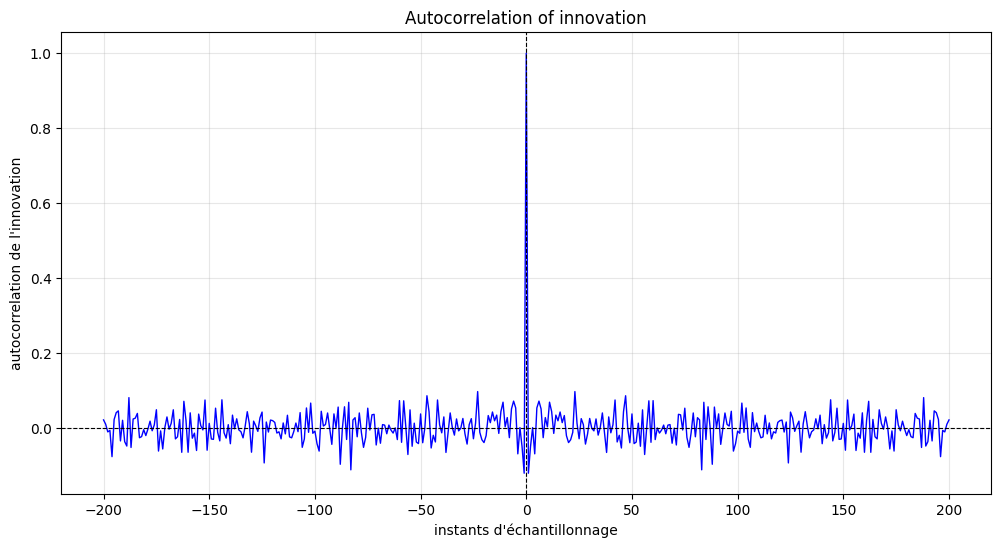

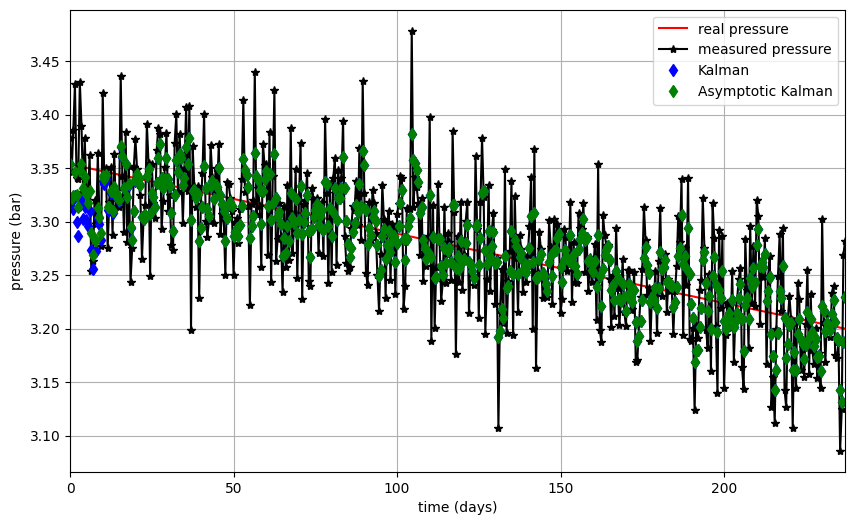

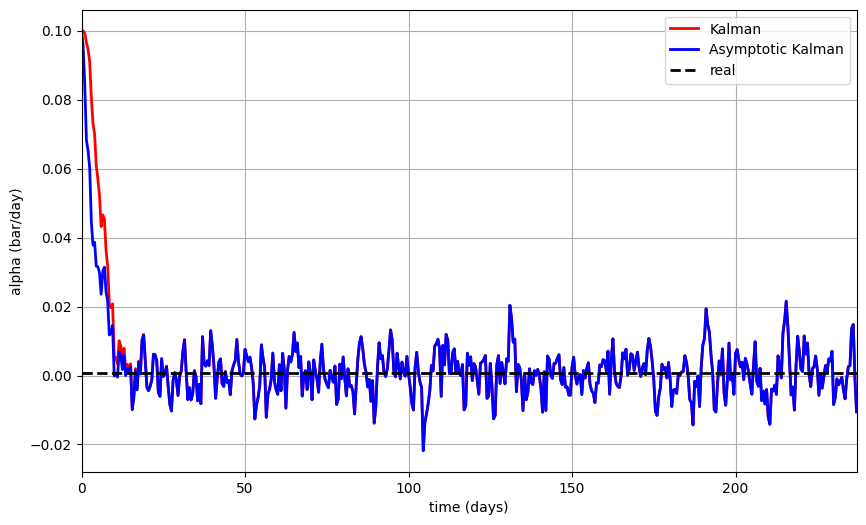

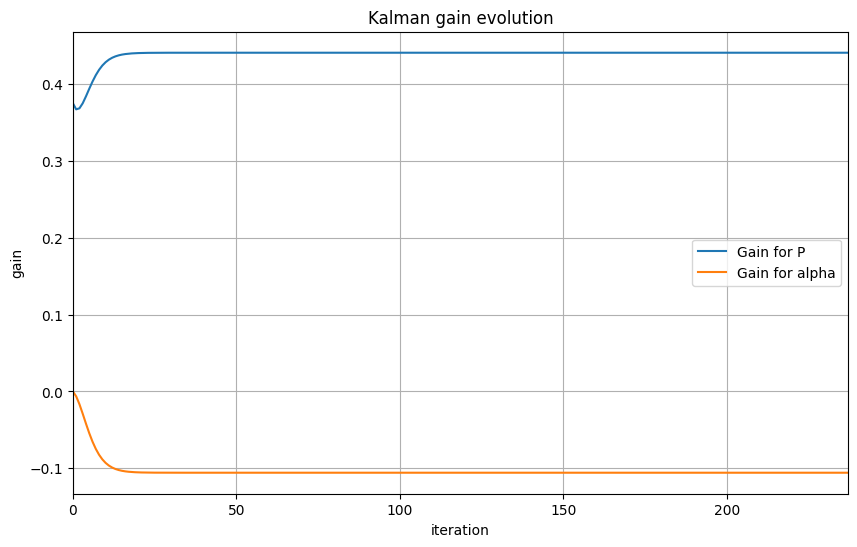

In [82]:
# add autocorrelation figure
# just check first x days
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# =========================
# 0. 基本设置
# =========================
plt.close('all')
np.random.seed(42)

# =========================
# 1. 读取真实系统初始值
# =========================
df = pd.read_csv("/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv", encoding="utf-8-sig")

# target_csemCur = 5002343705   # target csemCur
target_csemCur = 5000252545

df_csem = df[df['csemCur'] == target_csemCur].copy()

if df_csem.empty:
    raise ValueError(f"在 new_df_AlphaCorrected 中没有找到 csemCur = {target_csemCur} 的数据")

row0 = df_csem.iloc[0]

P0_true = float(row0['compensatedRelativePressure_mafiltered'])
alpha_true = float(row0['alpha'])

# =========================
# 2. 真实系统线性变化
# =========================
Te = 0.5 # sampling time (days)

if alpha_true <= 0:
    raise ValueError(f"alpha_true 必须大于 0，当前读取到的是 {alpha_true}")

tf = (P0_true - 3.2) / alpha_true

if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查 P0_true={P0_true} 和 alpha_true={alpha_true}"
    )

temps = np.arange(0, tf + Te, Te)
P_true = P0_true - temps * alpha_true

# 测量噪声
sigma_meas = 0.05
# sigma_meas = 0.02
P_measured = P_true + sigma_meas * np.random.randn(len(P_true))

# =========================
# 3. 压力图（完整范围）
# =========================
plt.figure(1, figsize=(10, 6))
plt.plot(temps, P_true, 'r', label='real pressure')
plt.plot(temps, P_measured, '*-k', label='measured pressure')

# =========================
# 4. Kalman filtering
# =========================
Q = Te * np.diag([0.01, 1e-3])
R = sigma_meas**2 * 10
Sigma_priori_init = np.diag([0.01, 1e-6])

alpha0 = 0.1
P0 = P0_true

x0 = np.array([[P0],
               [alpha0]])

Kalman_states = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])
Kalman_gain = np.empty((2, 0))

# 新增：保存 innovation
innovations = []

for k in range(len(temps) - 1):
    A = np.array([[1, -Te],
                  [0,  1]])

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    K = Sigma_priori @ H.T @ np.linalg.inv(np.array([[R]]) + H @ Sigma_priori @ H.T)
    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori

    innovation = np.array([[P_measured[k + 1]]]) - H @ x_priori
    innovations.append(float(innovation.item()))

    x_posteriori = x_priori + K @ innovation

    Kalman_states = np.hstack((Kalman_states, x_posteriori))
    Kalman_gain = np.hstack((Kalman_gain, K))

innovations = np.array(innovations)

P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]

plt.figure(1)
plt.plot(temps, P_Kalman, 'bd', label='Kalman')

# =========================
# 5. Asymptotic Kalman filter
# =========================
alpha0_2 = 0.1
P0_2 = P0_true

x0 = np.array([[P0_2],
               [alpha0_2]])

Kalman_states2 = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])

K = Kalman_gain[:, -1].reshape(2, 1)

for k in range(len(temps) - 1):
    A = np.array([[1, -Te],
                  [0,  1]])

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori

    innovation = np.array([[P_measured[k + 1]]]) - H @ x_priori
    x_posteriori = x_priori + K @ innovation

    Kalman_states2 = np.hstack((Kalman_states2, x_posteriori))

P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]

plt.figure(1)
plt.plot(temps, P_Kalman2, 'gd', label='Asymptotic Kalman')
plt.xlabel('time (days)')
plt.ylabel('pressure (bar)')
plt.grid(True)
plt.legend()

# =========================
# 6. alpha 图
# =========================
plt.figure(2, figsize=(10, 6))
plt.plot(temps, alpha_Kalman, 'r', linewidth=2, label='Kalman')
plt.plot(temps, alpha_Kalman2, 'b', linewidth=2, label='Asymptotic Kalman')
plt.plot(temps, alpha_true * np.ones_like(temps), 'k--', linewidth=2, label='real')
plt.grid(True)
plt.xlabel('time (days)')
plt.ylabel('alpha (bar/day)')
plt.legend()

# =========================
# 7. Kalman gain 图
# =========================
plt.figure(3, figsize=(10, 6))
plt.plot(Kalman_gain[0, :], label='Gain for P')
plt.plot(Kalman_gain[1, :], label='Gain for alpha')
plt.title('Kalman gain evolution')
plt.xlabel('iteration')
plt.ylabel('gain')
plt.grid(True)
plt.legend()


# # 如果x轴单位是时间而不是迭代次数，你可以改成：
# plt.figure(3, figsize=(10, 6))
# plt.plot(temps[1:], Kalman_gain[0, :], label='Gain for P')
# plt.plot(temps[1:], Kalman_gain[1, :], label='Gain for alpha')
# plt.title('Kalman gain evolution')
# plt.xlabel('time (days)')
# plt.ylabel('gain')
# plt.grid(True)
# plt.legend()

# =========================
# 8. Innovation 序列
# =========================
plt.figure(4, figsize=(10, 6))
plt.plot(innovations, color='purple', linewidth=1.5)
plt.axhline(0, color='black', linestyle='--')
plt.title('Innovation sequence')
plt.xlabel('iteration')
plt.ylabel('innovation')
plt.grid(True)

# # =========================
# # 9. Innovation 自相关图
# # =========================
# plt.figure(5, figsize=(10, 6))
# plot_acf(innovations, lags=min(40, len(innovations) - 1), alpha=0.05)
# plt.title("Autocorrelation of innovation")


# =========================
# 9. Innovation 对称自相关图（带负 x 轴）
# =========================
x = np.asarray(innovations, dtype=float)
x = x - np.mean(x)   # 去均值

acf_full = np.correlate(x, x, mode='full')

# 归一化，让 lag=0 时等于 1
acf_full = acf_full / acf_full[len(x) - 1]

# 生成对称 lag 轴
lags = np.arange(-(len(x) - 1), len(x))

# 限制显示范围，和你截图更接近
max_lag = min(200, len(x) - 1)
mask = (lags >= -max_lag) & (lags <= max_lag)

plt.figure(5, figsize=(12, 6))
plt.plot(lags[mask], acf_full[mask], color='blue', linewidth=1)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel("instants d'échantillonnage")
plt.ylabel("autocorrelation de l'innovation")
plt.title("Autocorrelation of innovation")
plt.grid(True, alpha=0.3)




# =========================
# 10. 放大 x 轴前段
# =========================

x_max_zoom = min(300, temps[-1])

plt.figure(1)
plt.xlim(0, x_max_zoom)

plt.figure(2)
plt.xlim(0, x_max_zoom)

plt.figure(3)
plt.xlim(0, x_max_zoom)

# =========================
# 11. 打印关键信息
# =========================
print("target_csemCur =", target_csemCur)
print("P0_true =", P0_true)
print("alpha_true =", alpha_true)
print("tf =", tf)
print("x_max_zoom =", x_max_zoom)

plt.show()

target_csemCur = 5000252545
P0_true = 3.353635650097035
alpha_true = 0.0006485958289678
tf = 236.87424931723112
number of sampling instants = 238
x_max_zoom = 50


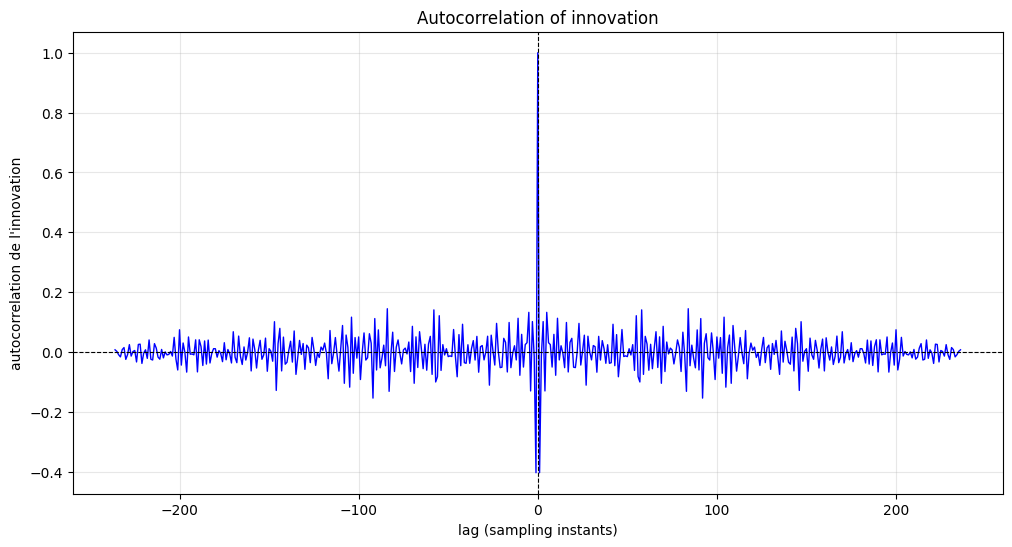

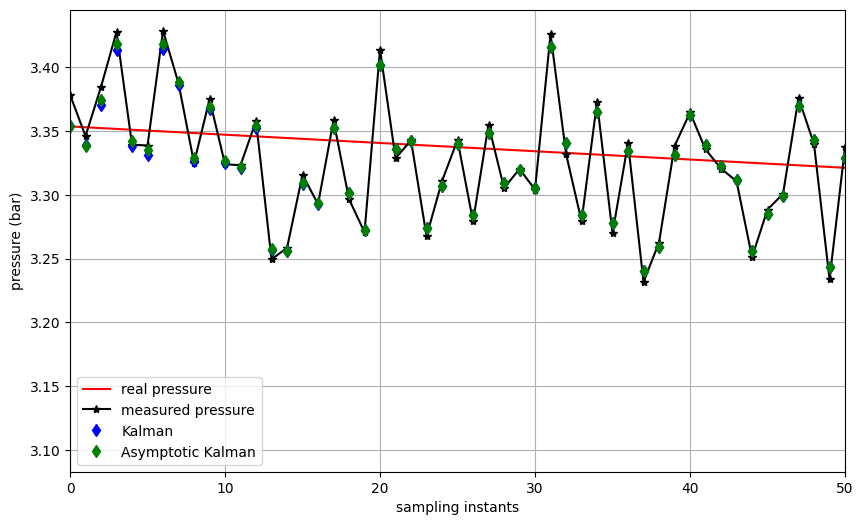

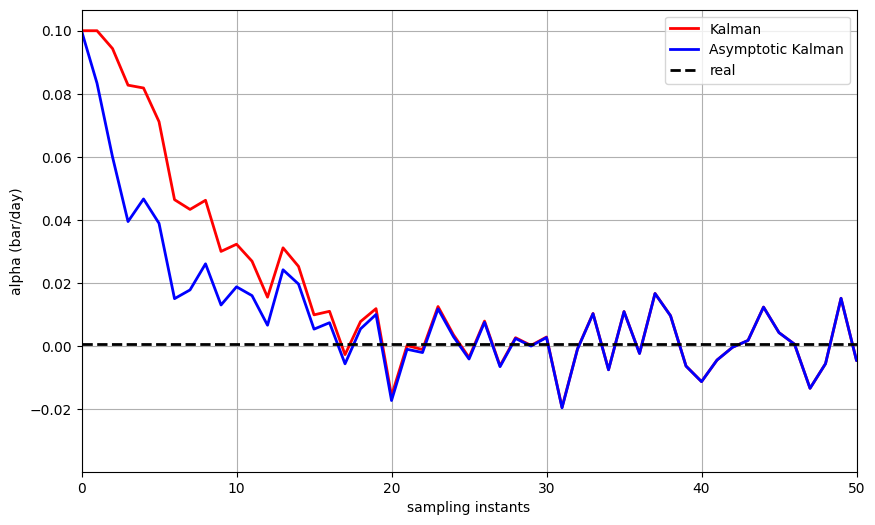

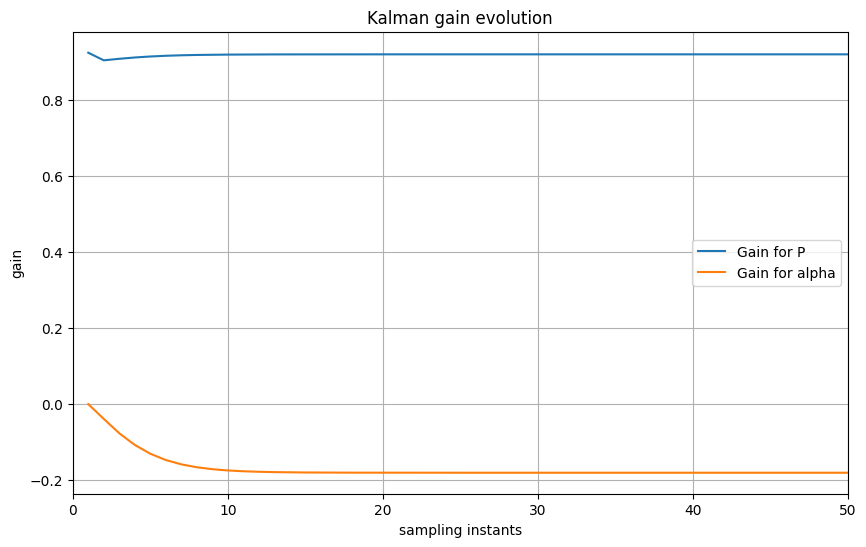

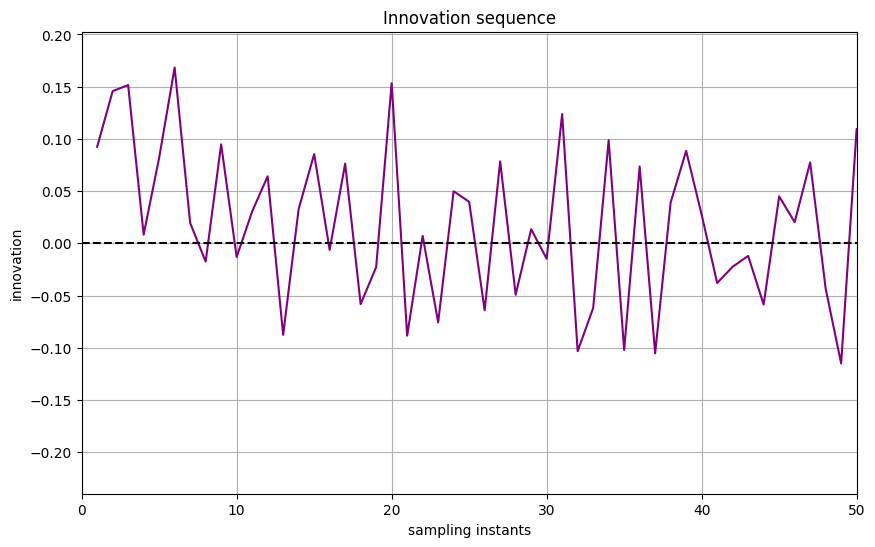

In [109]:
# add autocorrelation figure
# x-axis changed to sampling instants instead of time (days)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf


# =========================
# 0. 基本设置
# =========================
plt.close('all')
np.random.seed(42)


# =========================
# 1. 读取真实系统初始值
# =========================
df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv",
    encoding="utf-8-sig"
)

# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447

df_csem = df[df['csemCur'] == target_csemCur].copy()

if df_csem.empty:
    raise ValueError(f"在 new_df_AlphaCorrected 中没有找到 csemCur = {target_csemCur} 的数据")

row0 = df_csem.iloc[0]

P0_true = float(row0['compensatedRelativePressure_mafiltered'])
alpha_true = float(row0['alpha'])


# =========================
# 2. 真实系统线性变化
# =========================
Te = 1  # sampling time (days)

if alpha_true <= 0:
    raise ValueError(f"alpha_true 必须大于 0，当前读取到的是 {alpha_true}")

tf = (P0_true - 3.2) / alpha_true

if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查 P0_true={P0_true} 和 alpha_true={alpha_true}"
    )

temps = np.arange(0, tf + Te, Te)
sampling_instants = np.arange(len(temps))

P_true = P0_true - temps * alpha_true

# 测量噪声
sigma_meas = 0.05
# sigma_meas = 0.02
P_measured = P_true + sigma_meas * np.random.randn(len(P_true))


# =========================
# 3. 压力图（完整范围）
# =========================
plt.figure(1, figsize=(10, 6))
plt.plot(sampling_instants, P_true, 'r', label='real pressure')
plt.plot(sampling_instants, P_measured, '*-k', label='measured pressure')


# =========================
# 4. Kalman filtering
# =========================
Q = Te * np.diag([0.02, 1e-3])
R = sigma_meas**2 
Sigma_priori_init = np.diag([0.01, 1e-6])

alpha0 = 0.1
P0 = P0_true

x0 = np.array([
    [P0],
    [alpha0]
])

Kalman_states = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])
Kalman_gain = np.empty((2, 0))

# 保存 innovation
innovations = []

for k in range(len(temps) - 1):
    A = np.array([
        [1, -Te],
        [0,  1]
    ])

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    K = Sigma_priori @ H.T @ np.linalg.inv(np.array([[R]]) + H @ Sigma_priori @ H.T)
    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori

    innovation = np.array([[P_measured[k + 1]]]) - H @ x_priori
    innovations.append(float(innovation.item()))

    x_posteriori = x_priori + K @ innovation

    Kalman_states = np.hstack((Kalman_states, x_posteriori))
    Kalman_gain = np.hstack((Kalman_gain, K))

innovations = np.array(innovations)

P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]

plt.figure(1)
plt.plot(sampling_instants, P_Kalman, 'bd', label='Kalman')


# =========================
# 5. Asymptotic Kalman filter
# =========================
alpha0_2 = 0.1
P0_2 = P0_true

x0 = np.array([
    [P0_2],
    [alpha0_2]
])

Kalman_states2 = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()
H = np.array([[1, 0]])

K = Kalman_gain[:, -1].reshape(2, 1)

for k in range(len(temps) - 1):
    A = np.array([
        [1, -Te],
        [0,  1]
    ])

    x_priori = A @ x_posteriori
    Sigma_priori = A @ Sigma_posteriori @ A.T + Q

    Sigma_posteriori = (np.eye(2) - K @ H) @ Sigma_priori

    innovation = np.array([[P_measured[k + 1]]]) - H @ x_priori
    x_posteriori = x_priori + K @ innovation

    Kalman_states2 = np.hstack((Kalman_states2, x_posteriori))

P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]

plt.figure(1)
plt.plot(sampling_instants, P_Kalman2, 'gd', label='Asymptotic Kalman')
plt.xlabel('sampling instants')
plt.ylabel('pressure (bar)')
plt.grid(True)
plt.legend()


# =========================
# 6. alpha 图
# =========================
plt.figure(2, figsize=(10, 6))
plt.plot(sampling_instants, alpha_Kalman, 'r', linewidth=2, label='Kalman')
plt.plot(sampling_instants, alpha_Kalman2, 'b', linewidth=2, label='Asymptotic Kalman')
plt.plot(sampling_instants, alpha_true * np.ones_like(sampling_instants), 'k--', linewidth=2, label='real')
plt.grid(True)
plt.xlabel('sampling instants')
plt.ylabel('alpha (bar/day)')
plt.legend()


# =========================
# 7. Kalman gain 图
# =========================
sampling_instants_gain = np.arange(1, len(temps))

plt.figure(3, figsize=(10, 6))
plt.plot(sampling_instants_gain, Kalman_gain[0, :], label='Gain for P')
plt.plot(sampling_instants_gain, Kalman_gain[1, :], label='Gain for alpha')
plt.title('Kalman gain evolution')
plt.xlabel('sampling instants')
plt.ylabel('gain')
plt.grid(True)
plt.legend()


# =========================
# 8. Innovation 序列
# =========================
sampling_instants_innov = np.arange(1, len(temps))

plt.figure(4, figsize=(10, 6))
plt.plot(sampling_instants_innov, innovations, color='purple', linewidth=1.5)
plt.axhline(0, color='black', linestyle='--')
plt.title('Innovation sequence')
plt.xlabel('sampling instants')
plt.ylabel('innovation')
plt.grid(True)


# # =========================
# # 9. Innovation 自相关图
# # =========================
# plt.figure(5, figsize=(10, 6))
# plot_acf(innovations, lags=min(40, len(innovations) - 1), alpha=0.05)
# plt.title("Autocorrelation of innovation")
# plt.xlabel('lag (sampling instants)')


# =========================
# 9. Innovation 对称自相关图（带负 x 轴）
# =========================
x = np.asarray(innovations, dtype=float)
x = x - np.mean(x)

acf_full = np.correlate(x, x, mode='full')
acf_full = acf_full / acf_full[len(x) - 1]

lags = np.arange(-(len(x) - 1), len(x))

max_lag = min(2000, len(x) - 1)
mask = (lags >= -max_lag) & (lags <= max_lag)

plt.figure(5, figsize=(12, 6))
plt.plot(lags[mask], acf_full[mask], color='blue', linewidth=1)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel("lag (sampling instants)")
plt.ylabel("autocorrelation de l'innovation")
plt.title("Autocorrelation of innovation")
plt.grid(True, alpha=0.3)


# =========================
# 10. 放大 x 轴前段
# =========================
x_max_zoom = min(50, len(sampling_instants) - 1)

plt.figure(1)
plt.xlim(0, x_max_zoom)

plt.figure(2)
plt.xlim(0, x_max_zoom)

plt.figure(3)
plt.xlim(0, x_max_zoom)

plt.figure(4)
plt.xlim(0, x_max_zoom)


# =========================
# 11. 打印关键信息
# =========================
print("target_csemCur =", target_csemCur)
print("P0_true =", P0_true)
print("alpha_true =", alpha_true)
print("tf =", tf)
print("number of sampling instants =", len(sampling_instants))
print("x_max_zoom =", x_max_zoom)

plt.show()